# 02 · Modelling: fearfulness classification
Runs `scripts/train_tabular.py` (baseline, Logistic Regression, Random Forest × three feature sets, 5-fold CV tuning on the 80% training split, one evaluation on the 20% held-out split).

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from catsense import config as C, data
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 40, "display.width", 160)
from IPython.display import Image, display

In [2]:
!cd .. && {sys.executable} scripts/train_tabular.py 2>/dev/null | tail -30

demographic  baseline       cv_f1=0.333 test_f1=0.332 auc=0.500 (1.6s)
demographic  logreg         cv_f1=0.589 test_f1=0.570 auc=0.592 (1.3s)
demographic  random_forest  cv_f1=0.591 test_f1=0.594 auc=0.629 (12.9s)
behaviour    baseline       cv_f1=0.333 test_f1=0.332 auc=0.500 (0.2s)
behaviour    logreg         cv_f1=0.758 test_f1=0.751 auc=0.844 (1.3s)
behaviour    random_forest  cv_f1=0.750 test_f1=0.763 auc=0.843 (21.4s)
combined     baseline       cv_f1=0.333 test_f1=0.332 auc=0.500 (0.2s)
combined     logreg         cv_f1=0.759 test_f1=0.758 auc=0.844 (1.6s)
combined     random_forest  cv_f1=0.752 test_f1=0.758 auc=0.844 (22.2s)
selected by CV: logreg on combined
             feature_set         model  n_features  cv_macro_f1  accuracy  precision  recall    f1  macro_f1  roc_auc  tuning_time_s  predict_ms_per_cat
             demographic      baseline           5        0.333     0.497      0.000   0.000 0.000     0.332    0.500          1.602               0.006
             demo

In [3]:
res = pd.read_csv(C.RESULTS / 'tabular_results.csv')
res.drop(columns='best_params').round(3)

,feature_set,model,n_features,cv_macro_f1,accuracy,precision,recall,f1,macro_f1,roc_auc,tuning_time_s,predict_ms_per_cat
0,demographic,baseline,5,0.333,0.497,0.000,0.000,0.000,0.332,0.500,1.602,0.006
1,demographic,logreg,5,0.589,0.571,0.570,0.602,0.585,0.570,0.592,1.251,0.007
2,demographic,random_forest,5,0.591,0.594,0.596,0.598,0.597,0.594,0.629,12.852,0.035
3,behaviour,baseline,106,0.333,0.497,0.000,0.000,0.000,0.332,0.500,0.165,0.004
4,behaviour,logreg,106,0.758,0.751,0.756,0.747,0.751,0.751,0.844,1.326,0.005
5,behaviour,random_forest,106,0.750,0.764,0.746,0.805,0.774,0.763,0.843,21.378,0.091
6,combined,baseline,111,0.333,0.497,0.000,0.000,0.000,0.332,0.500,0.201,0.008
7,combined,logreg,111,0.759,0.758,0.764,0.752,0.758,0.758,0.844,1.562,0.009
8,combined,random_forest,111,0.752,0.758,0.749,0.782,0.765,0.758,0.844,22.232,0.085
9,LEAKY (incl. fear items),logreg,125,0.977,0.981,0.979,0.984,0.982,0.981,0.999,1.446,0.006


In [4]:
res[['feature_set', 'model', 'best_params']]

,feature_set,model,best_params
0,demographic,baseline,"{""strategy"": ""most_frequent""}"
1,demographic,logreg,"{""C"": 0.1, ""l1_ratio"": 0.0}"
2,demographic,random_forest,"{""max_depth"": 10, ""min_samples_leaf"": 1, ""min_..."
3,behaviour,baseline,"{""strategy"": ""most_frequent""}"
4,behaviour,logreg,"{""C"": 0.1, ""l1_ratio"": 1.0}"
5,behaviour,random_forest,"{""max_depth"": 20, ""min_samples_leaf"": 1, ""min_..."
6,combined,baseline,"{""strategy"": ""most_frequent""}"
7,combined,logreg,"{""C"": 0.1, ""l1_ratio"": 1.0}"
8,combined,random_forest,"{""max_depth"": 20, ""min_samples_leaf"": 5, ""min_..."
9,LEAKY (incl. fear items),logreg,"{""clf__C"": 1, ""clf__l1_ratio"": 1.0}"


## Comparison

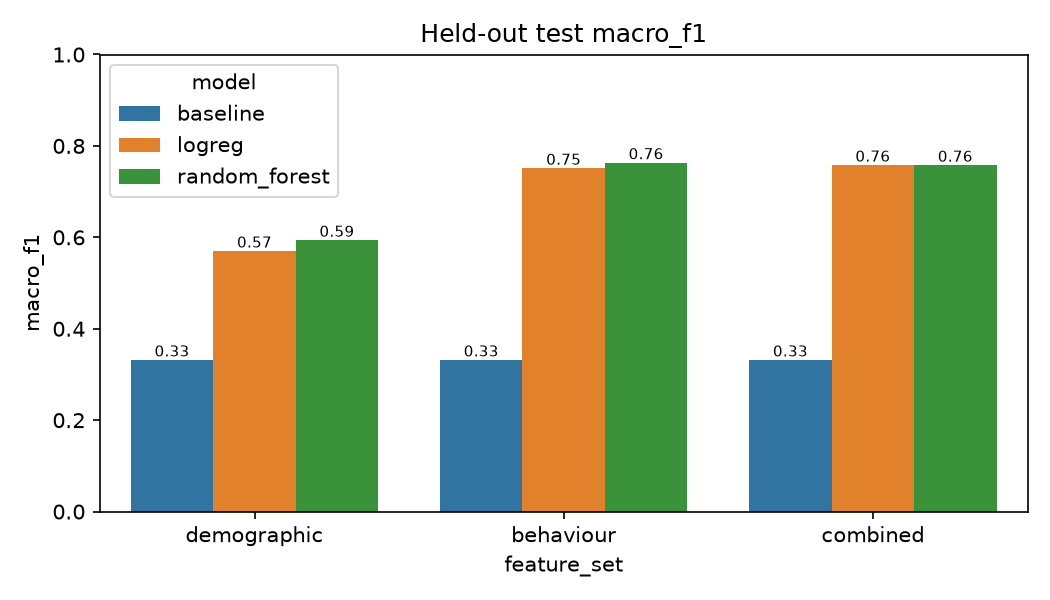

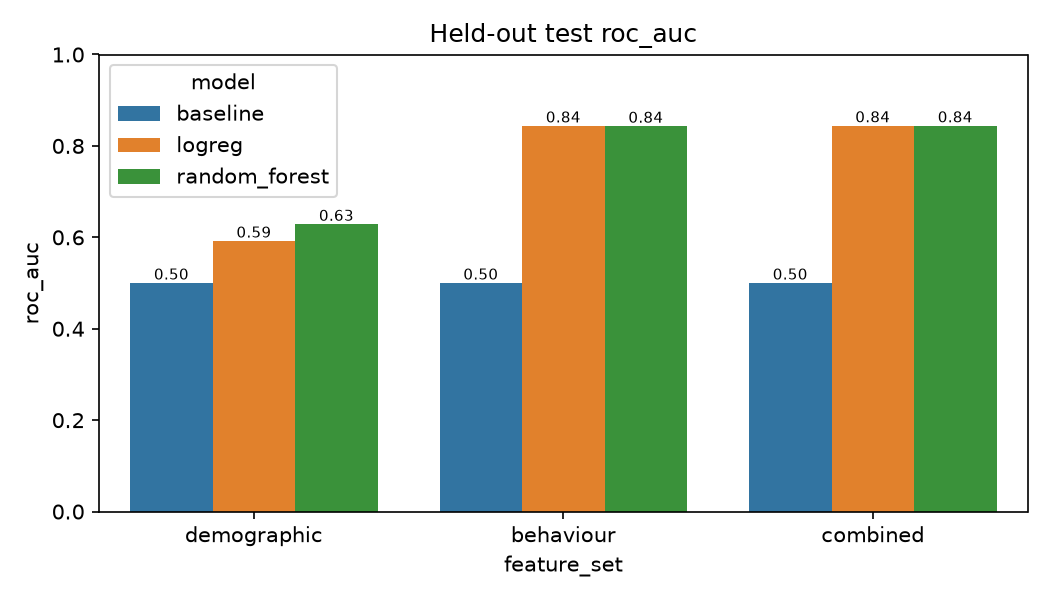

In [5]:
display(Image(C.FIGURES / 'tabular_macro_f1.png'))
display(Image(C.FIGURES / 'tabular_roc_auc.png'))

## Confusion matrices (combined features)

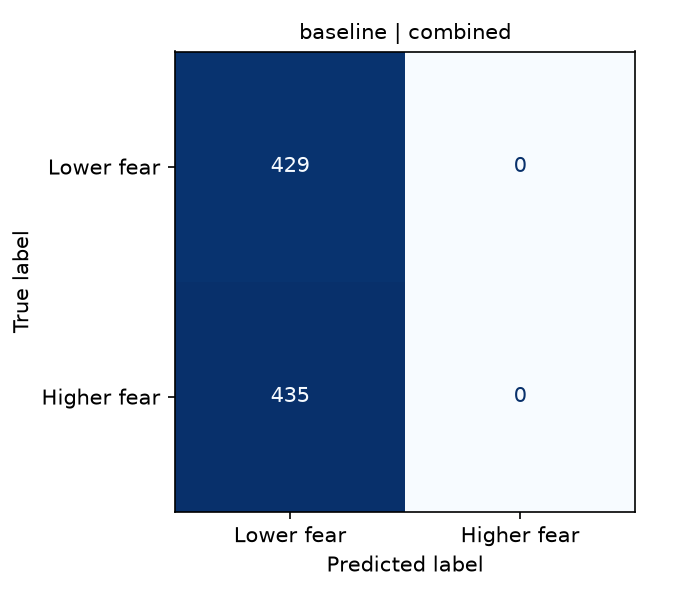

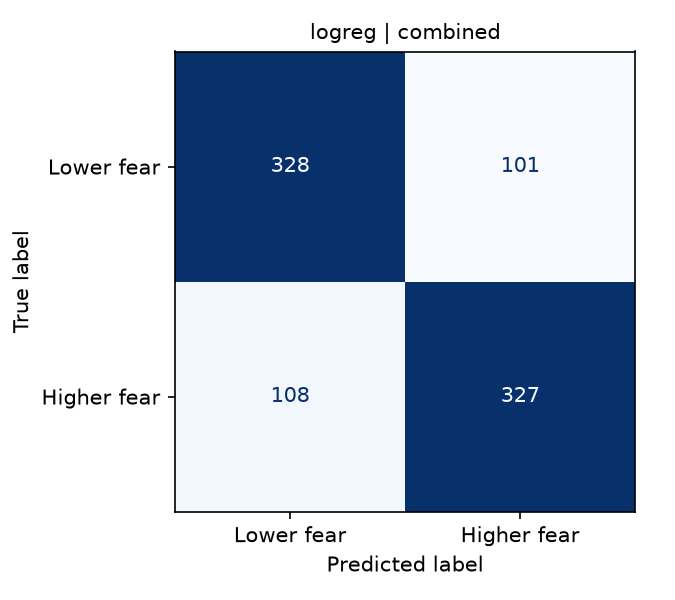

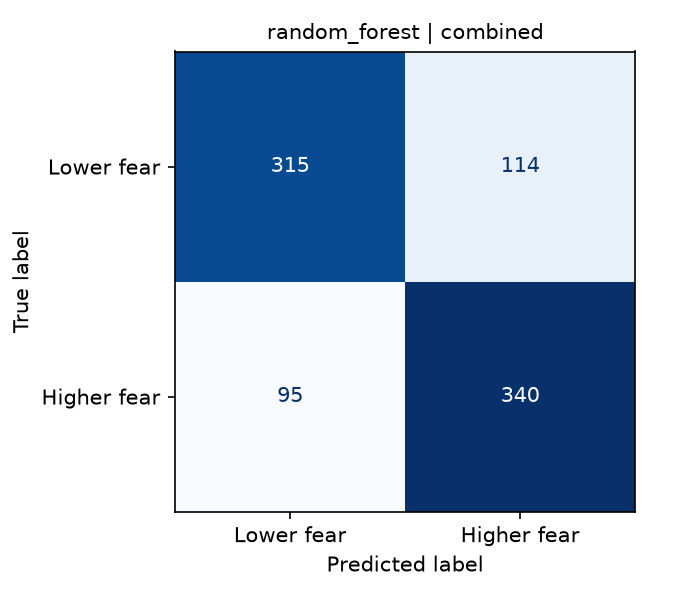

In [6]:
for m in ['baseline', 'logreg', 'random_forest']:
    display(Image(C.FIGURES / f'cm_combined_{m}.png', width=330))

## What drives the predictions?

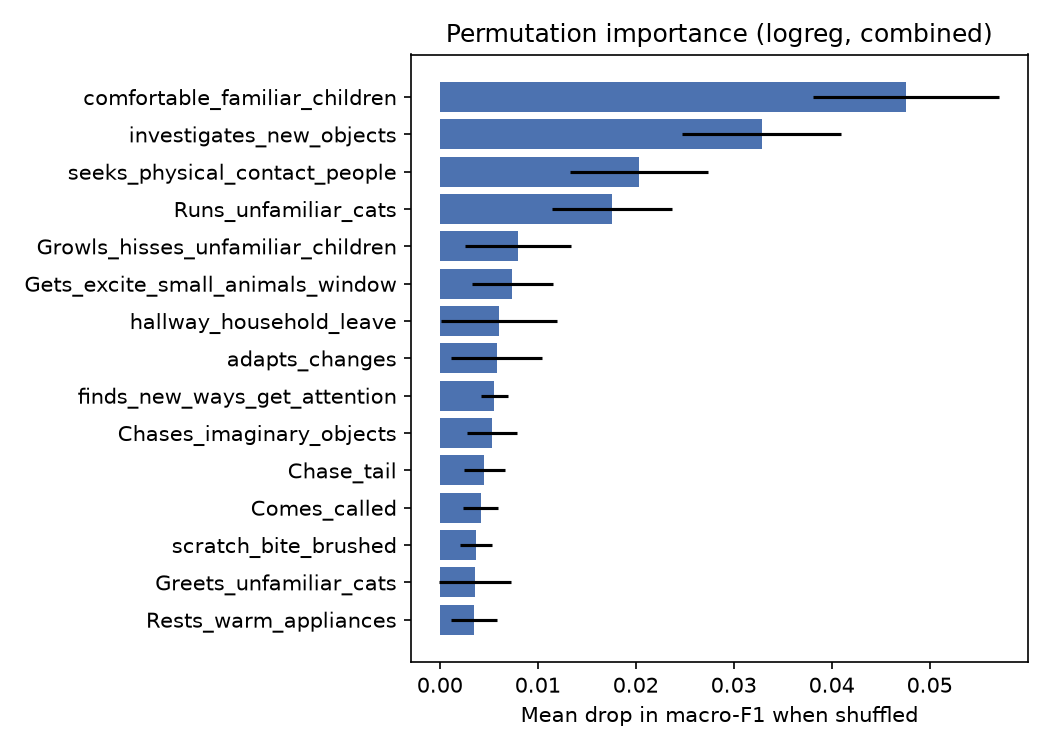

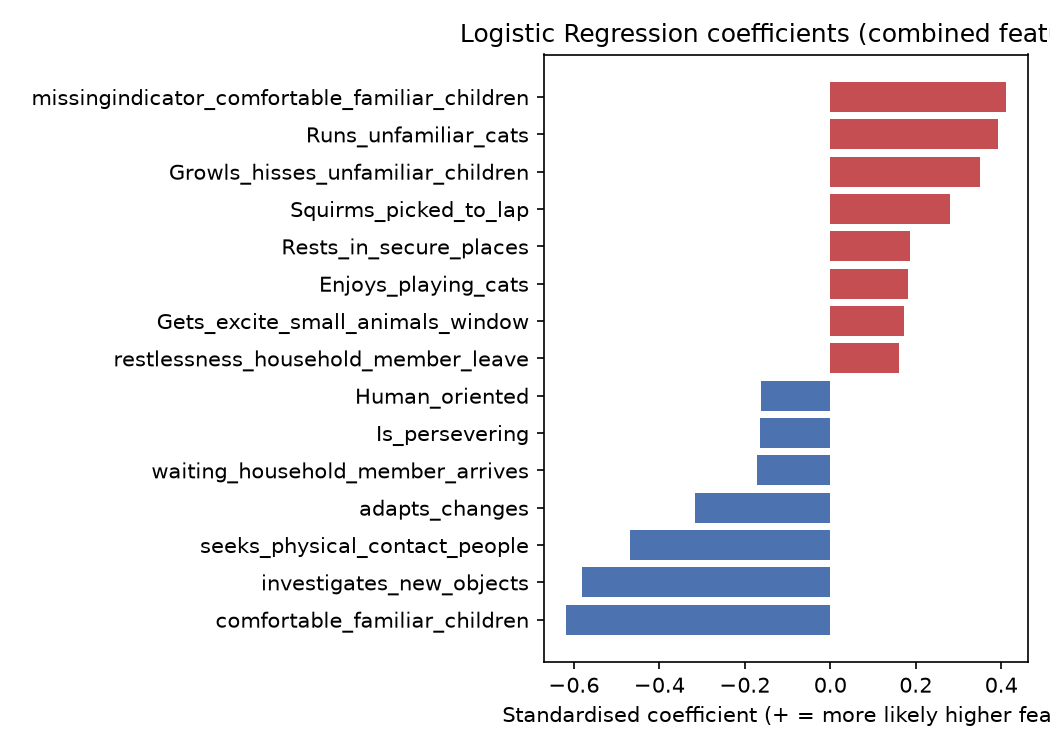

In [7]:
display(Image(C.FIGURES / 'permutation_importance.png'))
display(Image(C.FIGURES / 'logreg_coefficients.png'))

In [8]:
pd.read_csv(C.RESULTS / 'rf_impurity_importance.csv').head(15)

,Unnamed: 0,importance
0,investigates_new_objects,0.063296
1,adapts_changes,0.049017
2,comfortable_familiar_children,0.039882
3,seeks_physical_contact_people,0.039298
4,Runs_unfamiliar_cats,0.037752
5,Squirms_picked_to_lap,0.037249
6,Squirms_picked_held_arms,0.025372
7,AGE_BEHAVIOUR,0.024989
8,waiting_household_member_arrives,0.018030
9,Rests_in_secure_places,0.017036


## How short can a shelter intake form be?

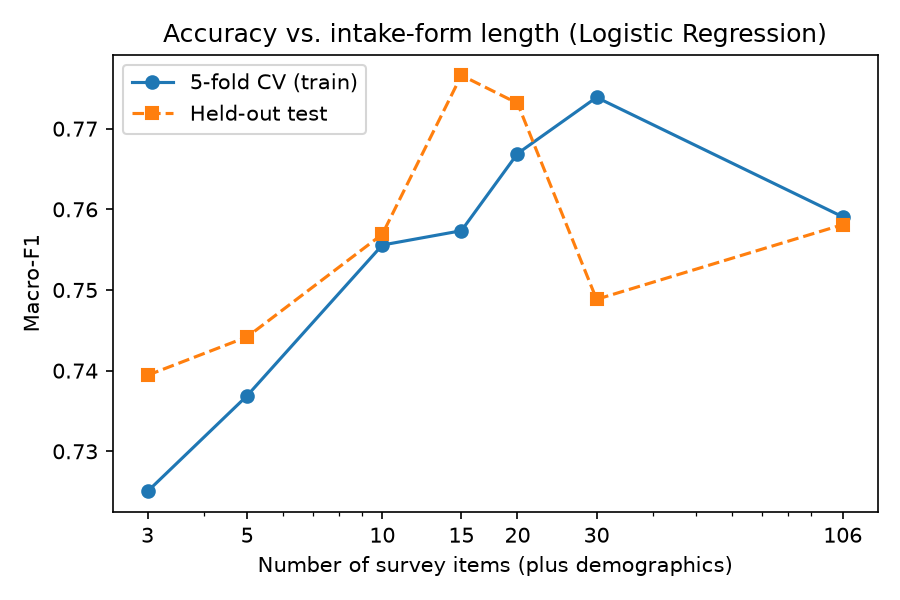

,k_items,cv_macro_f1,accuracy,precision,recall,f1,macro_f1,roc_auc
0,3,0.725,0.740,0.757,0.710,0.733,0.739,0.807
1,5,0.737,0.744,0.755,0.729,0.742,0.744,0.822
2,10,0.756,0.757,0.756,0.763,0.760,0.757,0.840
3,15,0.757,0.777,0.780,0.775,0.777,0.777,0.851
4,20,0.767,0.773,0.779,0.768,0.773,0.773,0.851
5,30,0.774,0.749,0.753,0.745,0.749,0.749,0.842
6,106,0.759,0.758,0.764,0.752,0.758,0.758,0.844


In [9]:
display(Image(C.FIGURES / 'compact_form_tradeoff.png'))
pd.read_csv(C.RESULTS / 'compact_form_results.csv').round(3)

## Error analysis by group (bias check)

In [10]:
sub = pd.read_csv(C.RESULTS / 'subgroup_errors.csv')
sub.round(3)

,attribute,group,n,high_fear_rate,accuracy,false_negative_rate,false_positive_rate
0,SEX,Female,418,0.493,0.763,0.218,0.255
1,SEX,Male,446,0.513,0.753,0.275,0.217
2,age_band,1-3,192,0.464,0.781,0.270,0.175
3,age_band,11+,118,0.458,0.678,0.296,0.344
4,age_band,3-7,268,0.545,0.791,0.185,0.238
5,age_band,7-11,172,0.610,0.738,0.229,0.313
6,age_band,<1,85,0.306,0.765,0.500,0.119
7,age_band,NaN,29,0.517,0.724,0.267,0.286
8,OTHER_CATS,NO,148,0.480,0.703,0.338,0.260
9,OTHER_CATS,YES,526,0.530,0.768,0.226,0.239


## Leakage demonstration
Including the 19 target-defining items gives near-perfect scores, which shows why they must be excluded: such a model would only rebuild the questionnaire score, not learn anything new.

In [11]:
res[res.feature_set.str.startswith('LEAKY')].drop(columns='best_params').round(3)

,feature_set,model,n_features,cv_macro_f1,accuracy,precision,recall,f1,macro_f1,roc_auc,tuning_time_s,predict_ms_per_cat
9,LEAKY (incl. fear items),logreg,125,0.977,0.981,0.979,0.984,0.982,0.981,0.999,1.446,0.006
